# BLDC Six-Step Commutation: Alignment, Torque Ripple and Speed Control

`09_bldc_six_step` | level 3 | experiment id(s): `exp_09_bldc_six_step`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 3 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Explain six-step (120 degree) commutation: which two phases conduct in each 60 degree sector, and
  why the Hall sensor must be aligned with the back-EMF.
- Verify the commutation table against the ideal trapezoidal back-EMF, the steady-state speed formula
  and an energy balance.
- Quantify how back-EMF shape (flat-top width) and Hall misalignment change torque ripple, current and
  efficiency at a fixed operating point.
- Compare a single-loop speed PI with a cascade (speed PI, pair-current PI) on inrush current.

## 2. Real-World Engineering Problem

Low-cost BLDC drives (fans, pumps, power tools) use six-step commutation from three Hall sensors.
Two things go wrong in practice: the Hall sensors are mounted a few electrical degrees off, and the
back-EMF is not a perfect trapezoid. Both cost efficiency and add torque ripple. This notebook measures how
much, for one set of illustrative motor parameters, and checks that the model itself is right first.

## 3. Research Background

The BLDC drive and its modelling are covered in the machine-drive literature (Pillay and Krishnan,
1989; Krause et al., 2013). Six-step operation with an ideal trapezoid has constant torque per ampere
in each sector. Real machines differ in back-EMF shape and in commutation transients; the
model here deliberately omits the latter (see section 14).

## 4. Research Literature

Sources are cited for the machine equations and the commutation principle. The motor parameters are
illustrative, not from a datasheet, and no performance figure is taken from the sources.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| pillay1989 | Pillay, P.; Krishnan, R. (1989). Modeling, simulation, and analysis of permanent-magnet motor drives, Part II: The brushless DC motor drive. IEEE Transactions on Industry Applications, 25(2), 274-279. doi:10.1109/28.25542. | Phase-variable BLDC model with trapezoidal back-EMF used for drive simulation. | Abstract-level verification only; the equations used here were written independently from the standard model. | verified (2026-11-25, web search of publisher/index/library record). Index record gives venue, volume, issue, pages and DOI. |
| krause2013 | Krause, P. C.; Wasynczuk, O.; Sudhoff, S. D.; Pekarek, S. D. (2013). Analysis of Electric Machinery and Drive Systems, 3rd ed.. Wiley-IEEE Press. ISBN 978-1-118-02429-4. | Reference-frame theory, PMSM and BLDC models, averaged converter models. | Textbook; parameters for a specific machine must come from its datasheet. | verified (2026-11-25, web search of publisher/index/library record). Publisher-affiliated page and a retailer record agree on edition, year and ISBN. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

Star-connected, two phases conducting (high phase $h$, low phase $l$), averaged PWM duty $D$, phase
resistance $R$, inductance $L$, back-EMF constant $K_e$ (peak, mechanical), unit shape $f(\theta_e)$:
$$2L\,\dot I=DV_{dc}-2RI-K_e\omega\,(f_h-f_l),\qquad T_e=K_e(f_h-f_l)\,I,\qquad J\dot\omega=T_e-B\omega-T_l.$$
**Ideal trapezoid.** $f(\theta)=\mathrm{clip}(2\sin\theta,-1,1)$ has 120 degree flat tops. In a correctly
aligned 60 degree sector, $f_h=+1$ and $f_l=-1$, so $f_h-f_l=2$ and the torque constant is $k_t=2K_e$.

**Steady state** (constant duty, flat sector, $f_h-f_l=2$):
$$\omega=\frac{DV_{dc}-2RT_l/k_t}{k_t+2RB/k_t},\qquad I=\frac{T_l+B\omega}{k_t}.$$
**Energy balance** at steady state: $DV_{dc}I=2RI^2+k_t\omega I$ (copper loss plus electromagnetic power).

**Ripple and efficiency.** Torque ripple $=(T_{max}-T_{min})/\bar T$ over a window at steady state;
efficiency $\eta=T_l\bar\omega/\overline{V_{dc}DI}$ (load power over averaged DC-bus power).

**Current loop.** Plant $1/(2Ls+2R)$ in amperes per volt, volts $=DV_{dc}$: PI with $k_p=2L\omega_c/V_{dc}$,
$k_i=2R\omega_c/V_{dc}$ (per unit duty). Speed loop as in notebook 06 with $k_t=2K_e$.

## 6. System Modeling

Library `BLDCMotor` with defaults: `R = 0.4 ohm`, `L = 0.8 mH` (per phase), `Ke = 0.02`, 4 pole pairs,
`J = 1.5e-5`, `B = 1e-6`, `Vdc = 24 V`, internal step 20 microseconds (RK4). Controller sample time 100 microseconds
(5 internal steps). Stall current at full duty is `Vdc / (2R) = 30 A`; the torque constant is `kt = 0.04 N m/A`.
Hall misalignment is applied as an electrical-degree offset in the sector decoder.

## 7. Dataset and Measurement Data

No dataset; simulated motor with illustrative parameters. No noise is applied.

## 8. Algorithm Architecture

Controllers: **A** single-loop PI (speed to duty); **B** cascade (speed PI to pair-current reference
limited to 6 A, pair-current PI at 200 Hz to duty), using the same `CascadeSpeedController` as notebook 06.

## 9. Algorithm Implementation

In [2]:
from control_lab.controllers import PID, CascadeSpeedController
from control_lab.controllers.foc import speed_loop_gains
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.metrics import iae, step_response_metrics
from control_lab.motors import BLDCMotor
from control_lab.motors.bldc import BLDCParams, SECTOR_PAIRS, hall_sector, trapezoid_shape
from control_lab.simulation import run_closed_loop
import pandas as pd

EXP = "exp_09_bldc_six_step"
P0 = BLDCParams()
N_SUB, DT_IN = 5, 20e-6
TS = N_SUB * DT_IN
KT = 2 * P0.Ke
I_MAX = 6.0
W_REF, T_LOAD = 300.0, 0.05

class BLDCPlant:
    # controller-rate wrapper: holds duty and load over N_SUB internal steps
    def __init__(self, params=P0, hall_offset_deg=0.0):
        self.motor = BLDCMotor(params, dt=DT_IN); self.off = hall_offset_deg
    def reset(self): self.motor.reset()
    @property
    def y(self): return self.motor.y
    @property
    def current(self): return self.motor.current
    def step(self, u, d=0.0):
        for _ in range(N_SUB): self.motor.step(u, d, self.off)
        return self.y

def make_controller(kind, plant, p=P0):
    kt = 2 * p.Ke
    if kind == "A single-loop PI":
        K = p.Vdc / (kt + 2 * p.R * p.B / kt); tau = p.J * 2 * p.R / (kt ** 2 + 2 * p.R * p.B)
        lam = 1 / (2 * np.pi * 20.0)
        return PID(tau / (K * lam), tau / (K * lam) / tau, 0.0, Ts=TS, u_min=0.0, u_max=1.0, antiwindup="backcalc")
    kp_w, ki_w = speed_loop_gains(p.J, kt, 20.0); wc = 2 * np.pi * 200.0
    speed = PID(kp_w, ki_w, Ts=N_SUB * 5 * TS, u_min=0.0, u_max=I_MAX, antiwindup="backcalc")
    cur = PID(2 * p.L * wc / p.Vdc, 2 * p.R * wc / p.Vdc, Ts=TS, u_min=0.0, u_max=1.0, antiwindup="backcalc")
    return CascadeSpeedController(plant, speed, cur, N_SUB * 5)

def run(kind, params=P0, hall=0.0, t_end=0.5, tl=T_LOAD, w_ref=W_REF):
    plant = BLDCPlant(params, hall); ctl = make_controller(kind, plant, P0)
    n = int(round(t_end / TS))
    return run_closed_loop(plant, ctl, np.full(n, w_ref), TS, disturbance=np.full(n, tl),
                           record={"i": lambda p: p.current, "te": lambda p: p.motor.torque})

`BLDCPlant` makes the six-step motor look like a sampled plant to the same loop and controller code
used elsewhere. The Hall offset is a property of the plant (a mounting error), not of the controller.

## 10. Simulation and Numerical Analysis

Runs: model verification (commutation alignment, steady state, energy balance), the controller comparison
at nominal alignment, and a 5 x 3 grid of back-EMF flat-top width and Hall offset under the cascade controller.

## 11. Experimental Validation

Level: **software simulation**. Independent references: the analytic property of the trapezoid in
aligned sectors, the closed-form steady state and the energy balance. No hardware; the commutation
transient (current decay through the phase inductance at each sector change) is not modelled, so
torque ripple here is an optimistic lower bound for ripple caused by commutation.

## 12. Performance Evaluation

In [3]:
checks = []
# 1. commutation alignment: in every sector the selected pair sees f_h - f_l = 2
th = np.deg2rad(np.linspace(0, 359.9, 3600))
def pair_df(theta, off=0.0, flat=120.0):
    hi, lo = SECTOR_PAIRS[hall_sector(theta, off)]
    shifts = (0.0, -2 * np.pi / 3, 2 * np.pi / 3)
    return trapezoid_shape(theta + shifts[hi], flat) - trapezoid_shape(theta + shifts[lo], flat)
df_al = np.array([pair_df(t) for t in th])
sectors = np.array([hall_sector(t) for t in th])
checks.append(check("aligned: f_h - f_l = 2 at every angle (3600 angles, all six sectors visited)", np.allclose(df_al, 2.0, atol=1e-9) and set(sectors) == set(range(6)), f"max |df-2| = {np.max(np.abs(df_al - 2)):.1e}"))
checks.append(check("trapezoid_shape: flat top 120 deg wide, value 2 sin(theta) on the slope", abs(trapezoid_shape(np.deg2rad(90)) - 1) < 1e-12 and abs(trapezoid_shape(np.deg2rad(60)) - 1) < 1e-12 and abs(trapezoid_shape(np.deg2rad(15)) - 2 * np.sin(np.deg2rad(15))) < 1e-12, "hand values"))
# 2. steady state with fixed duty
D, TL = 0.5, 0.02
m = BLDCMotor(P0, dt=DT_IN)
for _ in range(int(0.6 / DT_IN)): m.step(D, TL)
w_th = (D * P0.Vdc - 2 * P0.R * TL / KT) / (KT + 2 * P0.R * P0.B / KT); i_th = (TL + P0.B * w_th) / KT
ws, is_, te_open = [], [], []
for _ in range(int(0.05 / DT_IN)): m.step(D, TL); ws.append(m.y); is_.append(m.current); te_open.append(m.torque)
te_open = np.array(te_open)
checks.append(check("steady-state speed equals the closed-form value (<0.1%)", abs(np.mean(ws) - w_th) / w_th < 1e-3, f"{np.mean(ws):.3f} vs {w_th:.3f} rad/s"))
checks.append(check("steady-state pair current equals (Tl + B w)/kt (<0.5%)", abs(np.mean(is_) - i_th) / i_th < 5e-3, f"{np.mean(is_):.4f} vs {i_th:.4f} A"))
p_in = D * P0.Vdc * np.mean(is_); p_cu = 2 * P0.R * np.mean(np.square(is_)); p_em = KT * np.mean(ws) * np.mean(is_)
checks.append(check("energy balance: D Vdc I = 2 R I^2 + kt w I (<0.5%)", abs(p_in - p_cu - p_em) / p_in < 5e-3, f"{p_in:.3f} W = {p_cu:.3f} + {p_em:.3f}"))

# 3. controller comparison, nominal alignment
rows = []; store = {}
for kind in ("A single-loop PI", "B cascade"):
    o = run(kind, t_end=0.5); store[kind] = o
    sp = step_response_metrics(o["t"], o["y"], W_REF)
    rows.append(dict(controller=kind, peak_current_A=float(o["i"].max()), overshoot_percent=sp["overshoot_percent"], settling_ms=None if sp["settling_time"] is None else sp["settling_time"] * 1e3,
                     ess_percent=100 * abs(W_REF - o["y"][-1]) / W_REF, iae=iae(o["t"], o["e"])))
dfc = pd.DataFrame(rows).set_index("controller"); print(dfc.round(3))
checks.append(check("single loop draws more than 2x the 6 A limit at start", dfc.loc["A single-loop PI", "peak_current_A"] > 2 * I_MAX, f"{dfc.loc['A single-loop PI', 'peak_current_A']:.1f} A"))
checks.append(check("cascade keeps the pair current within 15% of the limit", dfc.loc["B cascade", "peak_current_A"] < 1.15 * I_MAX, f"{dfc.loc['B cascade', 'peak_current_A']:.2f} A"))
for k in dfc.index: checks.append(check(f"{k}: steady-state speed error below 0.5%", dfc.loc[k, "ess_percent"] < 0.5, f"{dfc.loc[k, 'ess_percent']:.3f} %"))

# 4. grid: flat-top width x Hall offset (cascade)
grid = []
for flat in (120.0, 110.0, 100.0, 90.0, 80.0):
    for off in (0.0, 10.0, 20.0):
        o = run("B cascade", P0.with_changes(flat_deg=flat), hall=off, t_end=0.5)
        w = (o["t"] >= 0.35)
        te, i_, u_, y_ = o["te"][w], o["i"][w], o["u"][w], o["y"][w]
        grid.append(dict(flat_deg=flat, hall_offset_deg=off, torque_ripple_pp_percent=100 * float(np.ptp(te) / np.mean(te)), mean_current_A=float(np.mean(i_)),
                         mean_duty=float(np.mean(u_)), speed_ripple_pp_percent=100 * float(np.ptp(y_) / np.mean(y_)), mean_speed=float(np.mean(y_)),
                         efficiency=float(T_LOAD * np.mean(y_) / (P0.Vdc * np.mean(u_ * i_)))))
dg = pd.DataFrame(grid); print(dg.round(3).to_string(index=False))
g = dg.set_index(["flat_deg", "hall_offset_deg"])
floor_pred = 100 * (np.sqrt(3) / 2) * P0.p * np.mean(ws) * DT_IN        # percent: slope of the trapezoid x angle moved in one internal step
floor_open = 100 * float(np.ptp(te_open) / np.mean(te_open))
checks.append(check("open loop, constant duty: torque ripple equals the commutation-granularity floor (sqrt3/2) p w dt within 10%", abs(floor_open - floor_pred) / floor_pred < 0.10, f"measured {floor_open:.3f} % vs predicted {floor_pred:.3f} %"))
w_cl = g.loc[(120.0, 0.0), "mean_speed"]; floor_cl = 100 * (np.sqrt(3) / 2) * P0.p * w_cl * DT_IN
checks.append(check("ideal trapezoid, aligned, closed loop: torque ripple within 10% of the same floor", abs(g.loc[(120.0, 0.0), "torque_ripple_pp_percent"] - floor_cl) / floor_cl < 0.10, f"{g.loc[(120.0, 0.0), 'torque_ripple_pp_percent']:.3f} % vs {floor_cl:.3f} %"))
checks.append(check("narrower flat top (80 deg) gives more torque ripple than 120 deg at zero offset", g.loc[(80.0, 0.0), "torque_ripple_pp_percent"] > g.loc[(120.0, 0.0), "torque_ripple_pp_percent"], f"{g.loc[(80.0, 0.0), 'torque_ripple_pp_percent']:.2f} % vs {g.loc[(120.0, 0.0), 'torque_ripple_pp_percent']:.2f} %"))
checks.append(check("efficiency falls as Hall offset grows (120 deg flat: 0 > 10 > 20 degrees)", g.loc[(120.0, 0.0), "efficiency"] > g.loc[(120.0, 10.0), "efficiency"] > g.loc[(120.0, 20.0), "efficiency"], f"{g.loc[(120.0, 0.0), 'efficiency']:.3f}, {g.loc[(120.0, 10.0), 'efficiency']:.3f}, {g.loc[(120.0, 20.0), 'efficiency']:.3f}"))
for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], "|", c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

                  peak_current_A  overshoot_percent  settling_ms  ess_percent  \
controller                                                                      
A single-loop PI          12.870              0.001         36.5          0.0   
B cascade                  5.659              7.173         50.0          0.0   

                    iae  
controller               
A single-loop PI  2.571  
B cascade         4.522  


 flat_deg  hall_offset_deg  torque_ripple_pp_percent  mean_current_A  mean_duty  speed_ripple_pp_percent  mean_speed  efficiency
    120.0              0.0                     2.071           1.258      0.542                    0.001     300.000       0.917
    120.0             10.0                    19.128           1.277      0.535                    0.034     300.000       0.915
    120.0             20.0                    42.490           1.335      0.516                    0.094     300.000       0.908
    110.0              0.0                     8.918           1.264      0.539                    0.010     300.000       0.916
    110.0             10.0                    24.465           1.293      0.530                    0.053     300.000       0.913
    110.0             20.0                    46.010           1.361      0.508                    0.115     300.001       0.905
    100.0              0.0                    14.741           1.281      0.534                  

The first checks test the model against analytic results, including a derived floor on torque ripple;
the last ones test physically expected trends (more offset or a narrower flat top should not help). If a trend check had failed,
the right response would be to find out whether the model or my expectation was wrong.

## 13. Visualization and Interpretation

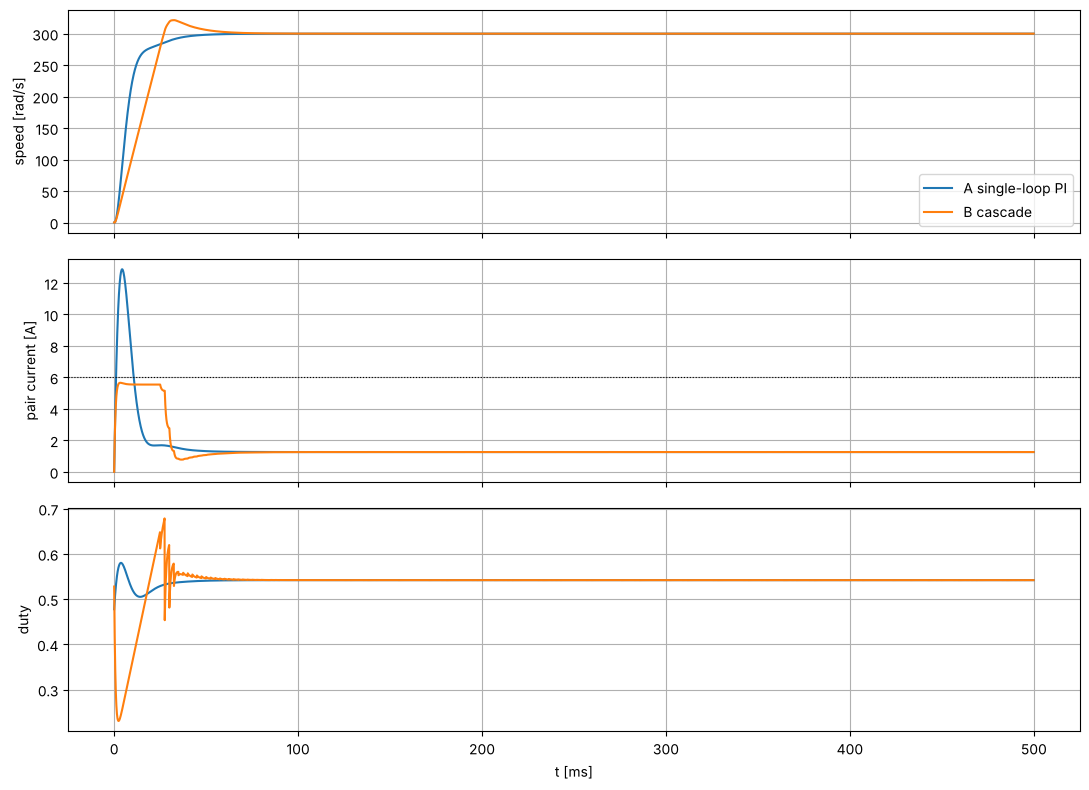

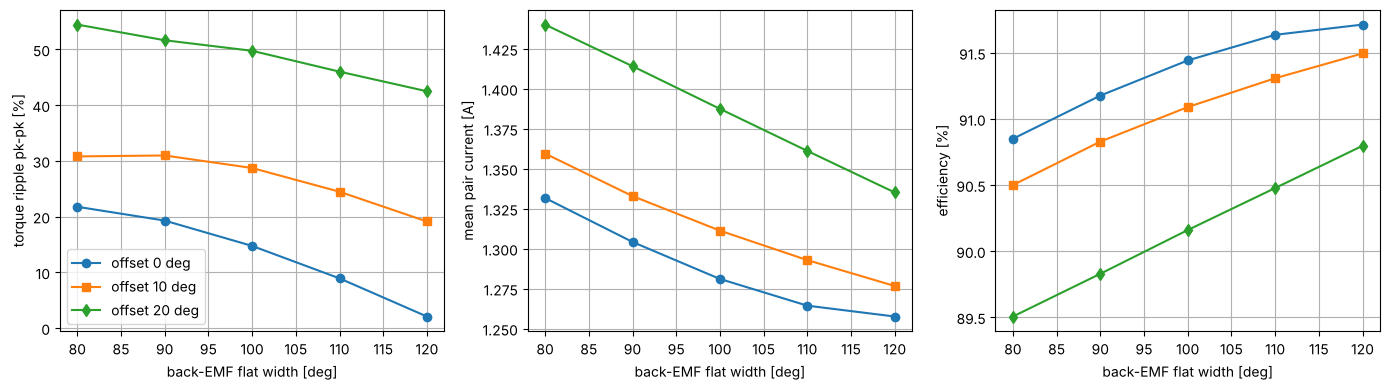

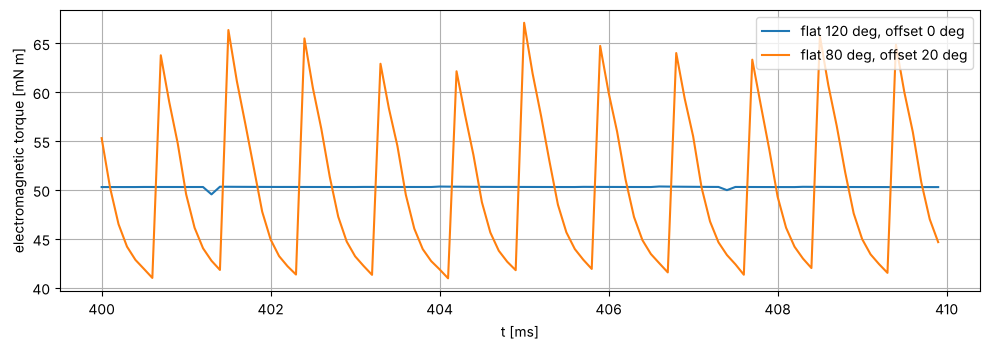

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for kind, o in store.items():
    ax[0].plot(o["t"] * 1e3, o["y"], label=kind); ax[1].plot(o["t"] * 1e3, o["i"]); ax[2].plot(o["t"] * 1e3, o["u"])
ax[0].set(ylabel="speed [rad/s]"); ax[1].set(ylabel="pair current [A]"); ax[2].set(ylabel="duty", xlabel="t [ms]"); ax[1].axhline(I_MAX, color="k", ls=":", lw=0.8)
ax[0].legend(); fig.tight_layout()
figs = [save_figure(fig, EXP, "startup")]
plt.show()
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for off, mk in zip((0.0, 10.0, 20.0), "osd"):
    s_ = dg[dg.hall_offset_deg == off]
    ax[0].plot(s_.flat_deg, s_.torque_ripple_pp_percent, mk + "-", label=f"offset {off:g} deg"); ax[1].plot(s_.flat_deg, s_.mean_current_A, mk + "-"); ax[2].plot(s_.flat_deg, 100 * s_.efficiency, mk + "-")
ax[0].set(xlabel="back-EMF flat width [deg]", ylabel="torque ripple pk-pk [%]"); ax[1].set(xlabel="back-EMF flat width [deg]", ylabel="mean pair current [A]"); ax[2].set(xlabel="back-EMF flat width [deg]", ylabel="efficiency [%]")
ax[0].legend(); fig.tight_layout()
figs.append(save_figure(fig, EXP, "ripple_current_efficiency"))
plt.show()
# one sector-level view of torque at the worst corner vs nominal
fig, ax = plt.subplots(figsize=(10, 3.6))
for flat, off in ((120.0, 0.0), (80.0, 20.0)):
    o = run("B cascade", P0.with_changes(flat_deg=flat), hall=off, t_end=0.5); w = (o["t"] >= 0.40) & (o["t"] < 0.41)
    ax.plot(o["t"][w] * 1e3, o["te"][w] * 1e3, label=f"flat {flat:g} deg, offset {off:g} deg")
ax.set(xlabel="t [ms]", ylabel="electromagnetic torque [mN m]"); ax.legend(); fig.tight_layout()
figs.append(save_figure(fig, EXP, "torque_waveforms"))
plt.show()

The last figure shows ten milliseconds, about nine commutations, of electromagnetic torque for the
best and the worst alignment/shape in the grid.

## 14. Research Discussion and Limitations

**Facts from this run.**
- **Model checks.** The aligned pair sees `f_h - f_l = 2` at all 3600 angles (error 1.3e-15). Steady-state speed
  289.875 against 289.855 rad/s (0.007%), current 0.5073 against 0.5072 A, and the energy balance closes
  (6.088 W in, 0.206 W copper, 5.882 W electromagnetic).
- **A torque-ripple floor from the model's time step.** Even a perfect trapezoid, perfect alignment and constant
  duty give 2.04% peak-to-peak torque ripple at 290 rad/s. It is not physical copper or iron behaviour: the sector is
  re-evaluated once per internal step (20 microseconds), so each commutation is late by up to one step, during
  which the old pair sits on the sloping part of its back-EMF. The predicted size
  `100 (sqrt(3)/2) p w dt` = 2.01% matches. It scales with speed times step, so it is a modelling floor to subtract when
  reading the grid, and my first threshold (2% in the check) failed for this reason before I traced it.
- **Hall misalignment (flat top 120 degrees).** 10 and 20 electrical degrees raise torque ripple to 19% and 42%
  (floor 2%), mean current by 1.5% and 6.1% and lower efficiency by 0.2 and 0.9 percentage points
  (0.917 to 0.915 to 0.908). Speed ripple stays below 0.1% because of the rotor inertia.
- **Back-EMF shape (zero offset).** Narrowing the flat top from 120 to 80 degrees raises torque ripple from 2.1% to
  21.8%, mean current by 5.9% and lowers efficiency by 0.9 points. The worst corner (80 degrees, 20 degrees offset) has
  54% torque ripple, 14.5% more current and 2.2 points lower efficiency.
- **Controllers.** Single loop: 12.9 A peak (43% of the 30 A stall current), 0% overshoot, settles in 36.5 ms. Cascade:
  5.66 A, 7.2% overshoot, 50 ms. Same trade as notebook 06.

**Inference (not tested).** The growth of ripple with offset is roughly linear over 0 to 20 degrees, and efficiency loss
is small here because copper loss is only about 8% of input power at this operating point; at lower speed and higher
load current the same misalignment would cost more efficiency.

**Limits.** (1) Ideal commutation: the current transition through the phase inductance at each sector change, which
in real six-step drives produces the dominant commutation torque dip, is not modelled, so ripple here is a lower
bound for that mechanism. (2) Efficiency counts only copper and friction, not switching, iron, or drive losses.
(3) Averaged PWM, no dead time. (4) Back-EMF shapes are clipped sines. (5) Illustrative parameters, no measurements, no
hardware. (6) One speed (300 rad/s) and one load (0.05 N m).

## 15. Summary, Exercises, and Further Research

**Key insights.** In a six-step drive the sensor alignment and the back-EMF shape set the
torque per ampere; a model that gets the aligned case exactly right (flat sector, closed-form
steady state, energy balance) is the base for measuring what misalignment costs.

**Exercises.** (1) Add a commutation current decay (finite `2L/R` transition) and re-measure ripple.
(2) Add a negative Hall offset and check symmetry. (3) Replace the pair-current PI by a hysteresis
current controller. (4) Add the 6-sector speed estimate from the Hall edges and the resulting delay.

**Related.** DC motor (06), PMSM FOC (10), conveyor (11).
**Research directions.** Commutation-torque-ripple minimisation and sensorless six-step
(back-EMF zero-crossing) drives.

In [5]:
rec_ = ExperimentRecord(
    experiment_id=EXP, title="BLDC six-step commutation: alignment, ripple, efficiency and cascade control",
    notebook="notebooks/04_motor_control/09_bldc_six_step.ipynb",
    algorithm="Six-step commutation with Hall sectors; PI and cascade PI speed control",
    application="Low-cost BLDC drive (illustrative)", plant_model="Averaged-PWM BLDC, trapezoidal back-EMF, ideal commutation (RK4, 20 us)",
    dataset={"name": "none", "kind": "simulated", "description": "Simulated motor, illustrative parameters."},
    metrics={"controllers": rows, "grid": grid, "commutation_floor": {"measured_open_loop_percent": floor_open, "predicted_open_loop_percent": float(floor_pred), "predicted_closed_loop_percent": float(floor_cl)}, "steady_state_check": {"w_sim": float(np.mean(ws)), "w_theory": float(w_th), "i_sim": float(np.mean(is_)), "i_theory": float(i_th)}},
    checks=checks, sampling_time_s=TS, random_seed=None, number_of_trials=len(rows) + len(grid),
    controller_parameters={"speed_bandwidth_hz": 20.0, "current_bandwidth_hz": 200.0, "current_limit_A": I_MAX},
    plant_parameters=P0.as_dict(), input_configuration={"speed_ref_rad_s": W_REF}, disturbance_configuration={"load_torque_Nm": T_LOAD},
    operating_conditions={"hall_offsets_deg": [0, 10, 20], "flat_widths_deg": [120, 110, 100, 90, 80]}, figure_references=figs,
    limitations=["Ideal commutation: commutation current transient and the resulting torque dip are not modelled.",
                 "Averaged PWM, no dead time, switch drops, iron loss or mutual inductance.",
                 "Trapezoid as clipped sine; real back-EMF shapes differ.", "Illustrative parameters; no measured data.", "No hardware validation."])
print(rec_.save())

experiments/results/exp_09_bldc_six_step.json
